# Lab 3: Pandas

(Last update: 6/12/2025)

Full name: Nguyễn Lê Hoàng Trung

Student ID: 23122004

---

**Summary**: In this assignment, you are going to learn how to use `Pandas`. Loops, and methods such as `apply/applymap` are not allowed to use unless specifically instructed to do so.

## 0. General instructions

### 0.0. Work on assignment

- You will do your assignment directly on this notebook file. First, you fill your name and student code at the beginning of the file. In this file, you will write your code when you see the following lines of code:

    ```python
    # TODO
    raise NotImplementedError()
    ```

    For optional coding parts, there will be:

    ```python
    # TODO (OPTIONAL)
    ```

    For markdown cell, there will be:

    ```markdown
    **TODO**: ...
    ```

- Of course, you have to remove the `raise NotImplementedError()` statement when you finish.

- For coding parts, there are often cells below to help you check your answers. You will pass the test if there are no errors when you run the test cells. In some cases, the tests are insufficient. That means if you do not pass the test, your answer is definitely wrong somewhere, but if you pass the test, your answer may still be incorrect.

- While doing the assignment, you should print out the output and create more cells for testing. But you have to remove all of them (comment your print-out codes, delete the cell created by you) when you submit your code. <font color=red>Do not remove or edit my cells</font> (except for the aforementioned cells).

- Keep your code clean and clear by using meaningful variable names and comments, not write too-long coding lines. Press `Ctrl + S` right after editing.

- **Keep it real**: The reason why you are here is to <font color=green>study, really study</font>. I highly recommend that you discuss your idea with your friends and <font color=green>write your own code based on your own knowledge</font>. <font color=red>Copy means zero.</font>

### 0.1. Submit your assignment

- When grading your assignment, I will choose `Kernel` - `Restart & Run All` in order to restart the kernel and run all cells in your notebook. Therefore, you should do that before submitting to ensure that the outputs are all as expected.

- After that, rename the notebook as `<StudentID>.ipynb`. For example, if your student code is 1234567, then your notebook is `1234567.ipynb`.

- Finally, submit your notebook file on Moodle. <font color=red>Please strictly follow the submission rules.</font>

---

## 1. Import libraries

In [1]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import warnings

warnings.simplefilter('ignore')

# TODO (OPTIONAL): Import your libraries

## 2. Data collection

- In this assignment, you are going to analyze **Mobiles Dataset (2025)**. You are provided the following files:
    - `./Mobiles Dataset (2025).csv`.

- Data source: [Mobiles Dataset (2025) - Kaggle](https://www.kaggle.com/datasets/abdulmalik1518/mobiles-dataset-2025).

## 3. Data pre-processing and exploration

- In this section, you are going to explore features of data. First, you have to read the data from `./Mobiles Dataset (2025).csv` and store it into a dataframe called `df`.

In [2]:
# Read data from ./Mobiles Dataset (2025).csv and save to df then display 5 first lines of data
try:
    df = pd.read_csv('./Mobiles Dataset (2025).csv', encoding='utf-8')
except UnicodeDecodeError:
    df = pd.read_csv('./Mobiles Dataset (2025).csv', encoding='latin1')
df.head()

,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (Pakistan),Launched Price (India),Launched Price (China),Launched Price (USA),Launched Year
0,Apple,iPhone 16 128GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,NaN,"INR 79,999","CNY 5,799",USD 799,2024
1,Apple,iPhone 16 256GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,NaN,"INR 84,999","CNY 6,099",USD 849,2024
2,Apple,iPhone 16 512GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,NaN,"INR 89,999","CNY 6,499",USD 899,2024
3,Apple,iPhone 16 Plus 128GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,NaN,"INR 89,999","CNY 6,199",USD 899,2024
4,Apple,iPhone 16 Plus 256GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,NaN,"INR 94,999","CNY 6,499",USD 949,2024


### 3.0. How many rows/columns are there in the dataset?

- Save the number of rows and columns to `n_rows, n_cols`

In [3]:
# Save your answer to n_rows, n_cols
n_rows, n_cols = df.shape
print(f"Number of rows: {n_rows}, Number of columns: {n_cols}")

Number of rows: 930, Number of columns: 14


In [4]:
# TEST
assert (n_rows, n_cols) == (930, 14)

### 3.1. Explore rows

- Is there any duplicate row? You will check it using `Pandas`.

In [5]:
# Save your answer to is_duplicate
is_duplicate = df.duplicated().any()
print(f"Are there duplicate rows? {is_duplicate}")

Are there duplicate rows? True


In [6]:
# TEST
assert is_duplicate == True

So there are duplicate rows. Delete them and keep only one using Pandas.

In [7]:
# Remove duplicate rows and keep only one
df = df.drop_duplicates()

In [8]:
# TEST
assert df.shape == (915, 14)

### 3.2. Explore columns

- Observe the data provided, carefully read the column titles as well as the data contained in the columns.
- Display the column names.

In [9]:
# Display the column names
print(df.columns)

Index(['Company Name', 'Model Name', 'Mobile Weight', 'RAM', 'Front Camera',
       'Back Camera', 'Processor', 'Battery Capacity', 'Screen Size',
       'Launched Price (Pakistan)', 'Launched Price (India)',
       'Launched Price (China)', 'Launched Price (USA)', 'Launched Year'],
      dtype='object')


### 3.3. Handle missing data & Convert data

- Next, we start handling missing data. First thing first, please display the data information.

In [10]:
# Display data information
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 915 entries, 0 to 929
Data columns (total 14 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Company Name               915 non-null    object 
 1   Model Name                 915 non-null    object 
 2   Mobile Weight              915 non-null    object 
 3   RAM                        915 non-null    object 
 4   Front Camera               915 non-null    object 
 5   Back Camera                915 non-null    object 
 6   Processor                  915 non-null    object 
 7   Battery Capacity           915 non-null    object 
 8   Screen Size                915 non-null    object 
 9   Launched Price (Pakistan)  0 non-null      float64
 10  Launched Price (India)     915 non-null    object 
 11  Launched Price (China)     915 non-null    object 
 12  Launched Price (USA)       915 non-null    object 
 13  Launched Year              915 non-null    int64  
dtyp

- Display number of NA values in each column.

In [11]:
# Display number of NA values in each column.
print(df.isna().sum())

Company Name                   0
Model Name                     0
Mobile Weight                  0
RAM                            0
Front Camera                   0
Back Camera                    0
Processor                      0
Battery Capacity               0
Screen Size                    0
Launched Price (Pakistan)    915
Launched Price (India)         0
Launched Price (China)         0
Launched Price (USA)           0
Launched Year                  0
dtype: int64


- As you can see, the Launched Price (Pakistan) column contains only NA values, so let's remove it.

In [12]:
# Remove Launched Price (Pakistan) column out of the df
if 'Launched Price (Pakistan)' in df.columns:
    df.drop(columns=['Launched Price (Pakistan)'], inplace=True)

In [13]:
# TEST
assert 'Launched Price (Pakistan)' not in df.columns

### 3.4. Value Parsing

Let's display the 5 first lines of data again.

In [14]:
# Display the 5 first lines of data
df.head()

,Company Name,Model Name,Mobile Weight,RAM,Front Camera,Back Camera,Processor,Battery Capacity,Screen Size,Launched Price (India),Launched Price (China),Launched Price (USA),Launched Year
0,Apple,iPhone 16 128GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"INR 79,999","CNY 5,799",USD 799,2024
1,Apple,iPhone 16 256GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"INR 84,999","CNY 6,099",USD 849,2024
2,Apple,iPhone 16 512GB,174g,6GB,12MP,48MP,A17 Bionic,"3,600mAh",6.1 inches,"INR 89,999","CNY 6,499",USD 899,2024
3,Apple,iPhone 16 Plus 128GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"INR 89,999","CNY 6,199",USD 899,2024
4,Apple,iPhone 16 Plus 256GB,203g,6GB,12MP,48MP,A17 Bionic,"4,200mAh",6.7 inches,"INR 94,999","CNY 6,499",USD 949,2024


For the columns Mobile Weight, RAM, Front Camera, Back Camera, Battery Capacity, Screen Size, and Launched Price, the values contain units. The numeric values should be extracted separately, and the corresponding units should be incorporated into the column names to ensure consistent and standardized data representation.

In [15]:
# Value Parsing

# Mobile Weight (g)
df['Mobile Weight'] = df['Mobile Weight'].str.replace('g', '', regex=False)
df['Mobile Weight'] = pd.to_numeric(df['Mobile Weight'], errors='coerce').astype(float).astype('int64')

# RAM (GB)
df['RAM'] = df['RAM'].str.replace('GB', '', regex=False)
df['RAM'] = pd.to_numeric(df['RAM'], errors='coerce').fillna(0).astype(float).astype('int64')

# Front Camera (MP)
df['Front Camera'] = df['Front Camera'].str.replace('MP', '', regex=False)
df['Front Camera'] = pd.to_numeric(df['Front Camera'], errors='coerce').fillna(0).astype(float).astype('int64')

# Back Camera (MP)
df['Back Camera'] = df['Back Camera'].str.replace('MP', '', regex=False)
df['Back Camera'] = pd.to_numeric(df['Back Camera'], errors='coerce').fillna(0).astype(float).astype('int64')

# Battery Capacity (mAh)
df['Battery Capacity'] = df['Battery Capacity'].str.replace('mAh', '', regex=False).str.replace(',', '', regex=False)
df['Battery Capacity'] = pd.to_numeric(df['Battery Capacity'], errors='coerce').fillna(0).astype(float).astype('int64')

# Screen Size (inches)
df['Screen Size'] = df['Screen Size'].str.replace(' inches', '', regex=False)
df['Screen Size'] = pd.to_numeric(df['Screen Size'], errors='coerce').astype('float64')

# Prices
df['Launched Price (India)'] = df['Launched Price (India)'].str.replace('INR ', '', regex=False).str.replace(',', '', regex=False)
df['Launched Price (India)'] = pd.to_numeric(df['Launched Price (India)'], errors='coerce').fillna(0).astype(float).astype('int64')

df['Launched Price (China)'] = df['Launched Price (China)'].str.replace('CNY ', '', regex=False).str.replace(',', '', regex=False)
df['Launched Price (China)'] = pd.to_numeric(df['Launched Price (China)'], errors='coerce').fillna(0).astype(float).astype('int64')

df['Launched Price (USA)'] = df['Launched Price (USA)'].str.replace('USD ', '', regex=False).str.replace(',', '', regex=False)
df['Launched Price (USA)'] = pd.to_numeric(df['Launched Price (USA)'], errors='coerce').fillna(0).astype(float).astype('int64')

# Rename Columns
df.rename(columns={
    'Mobile Weight': 'Mobile Weight (g)',
    'RAM': 'RAM (GB)',
    'Front Camera': 'Front Camera (MP)',
    'Back Camera': 'Back Camera (MP)',
    'Battery Capacity': 'Battery Capacity (mAh)',
    'Screen Size': 'Screen Size (inches)',
    'Launched Price (India)': 'Launched Price (India) (INR)',
    'Launched Price (China)': 'Launched Price (China) (CNY)',
    'Launched Price (USA)': 'Launched Price (USA) (USD)'
}, inplace=True)

print(df.dtypes)
df.head()

Company Name                     object
Model Name                       object
Mobile Weight (g)                 int64
RAM (GB)                          int64
Front Camera (MP)                 int64
Back Camera (MP)                  int64
Processor                        object
Battery Capacity (mAh)            int64
Screen Size (inches)            float64
Launched Price (India) (INR)      int64
Launched Price (China) (CNY)      int64
Launched Price (USA) (USD)        int64
Launched Year                     int64
dtype: object


,Company Name,Model Name,Mobile Weight (g),RAM (GB),Front Camera (MP),Back Camera (MP),Processor,Battery Capacity (mAh),Screen Size (inches),Launched Price (India) (INR),Launched Price (China) (CNY),Launched Price (USA) (USD),Launched Year
0,Apple,iPhone 16 128GB,174,6,12,48,A17 Bionic,3600,6.1,79999,5799,799,2024
1,Apple,iPhone 16 256GB,174,6,12,48,A17 Bionic,3600,6.1,84999,6099,849,2024
2,Apple,iPhone 16 512GB,174,6,12,48,A17 Bionic,3600,6.1,89999,6499,899,2024
3,Apple,iPhone 16 Plus 128GB,203,6,12,48,A17 Bionic,4200,6.7,89999,6199,899,2024
4,Apple,iPhone 16 Plus 256GB,203,6,12,48,A17 Bionic,4200,6.7,94999,6499,949,2024


In [16]:
# TEST (Simple check :p)
assert df["Mobile Weight (g)"].dtype == "int64"
assert df["RAM (GB)"].dtype == "int64"
assert df["Front Camera (MP)"].dtype == "int64"
assert df["Back Camera (MP)"].dtype == "int64"
assert df["Battery Capacity (mAh)"].dtype == "int64"
assert df["Launched Price (India) (INR)"].dtype == "int64"
assert df["Launched Price (China) (CNY)"].dtype == "int64"
assert df["Launched Price (USA) (USD)"].dtype == "int64"

assert df["Screen Size (inches)"].dtype == "float64"

assert df.loc[0, "Mobile Weight (g)"] == 174
assert df.loc[0, "RAM (GB)"] == 6
assert df.loc[0, "Front Camera (MP)"] == 12
assert df.loc[0, "Back Camera (MP)"] == 48
assert df.loc[0, "Battery Capacity (mAh)"] == 3600
assert df.loc[0, "Screen Size (inches)"] == 6.1
assert df.loc[0, "Launched Price (India) (INR)"] == 79999
assert df.loc[0, "Launched Price (China) (CNY)"] == 5799
assert df.loc[0, "Launched Price (USA) (USD)"] == 799

### 3.5. Data distribution

#### 3.4.1. Pie chart:

Visualize the pie chart showing the distribution of Company Name.

*You can create a different visualization that looks better than the sample visualization provided below.*


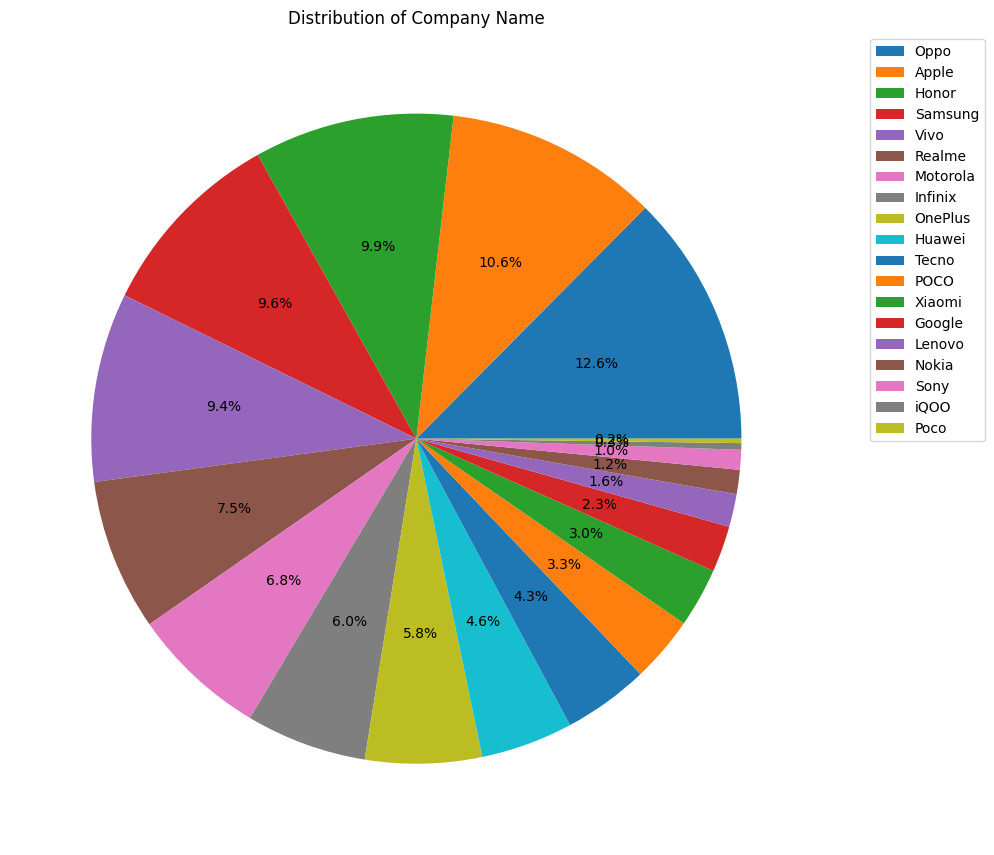

In [17]:
# Visualize the pie chart showing the distribution of Company Name
df['Company Name'].value_counts().plot.pie(
    labels=[''] * len(df['Company Name'].value_counts()),
    autopct='%1.1f%%',
    figsize=(10, 10),
    legend=True
)
plt.title('Distribution of Company Name')
plt.ylabel('')
plt.legend(
    labels=df['Company Name'].value_counts().index,
    bbox_to_anchor=(1.05, 1),
    loc='upper left'
)
plt.tight_layout()
plt.show()

- What is your insights about above pie chart?

The pie chart displays the distribution of mobile phone models by company. We can see that brands like Oppo, Apple, Honor, Samsung, and Vivo are the dominant players in this dataset, each contributing a significant portion of the total models. The top 3 companies alone account for approximately 33% of the dataset, indicating a somewhat concentrated market among these key manufacturers.

#### 3.4.2. Bar chart:

Comparison of Launched Prices (USD) across iPhone 16 Models.

*You can create a different visualization that looks better than the sample visualization provided below.*

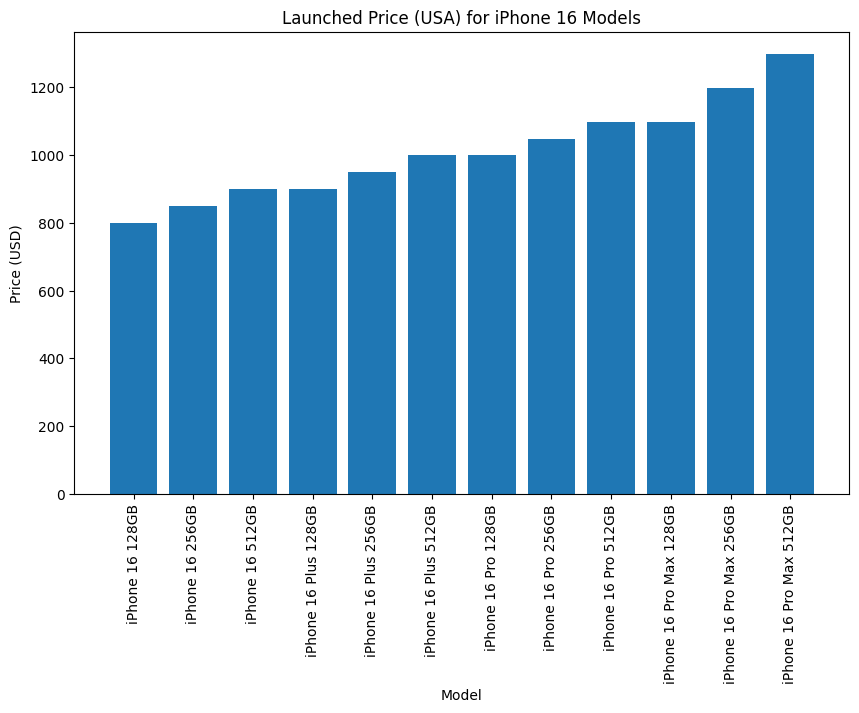

In [18]:
# Visualize the bar chart showing Launched Price (USA) (USD) for different iPhone 16 Models
iphone_16 = df[df['Model Name'].str.contains('iPhone 16')]
plt.figure(figsize=(10, 6))
plt.bar(iphone_16['Model Name'], iphone_16['Launched Price (USA) (USD)'])
plt.title('Launched Price (USA) for iPhone 16 Models')
plt.xlabel('Model')
plt.ylabel('Price (USD)')
plt.xticks(rotation=90)
plt.show()

- What is your insights about above visualization?

The bar chart clearly shows the price progression across the iPhone 16 lineup:

- There is about \$500 difference between the most affordable and most premium options in this dataset.

- There is a consistent price increase as we move from the base model to the Plus, Pro, and Pro Max variants, as well as with increased storage capacity.

- The chart reveals interesting "price plateaus" where different models share the same price point:
    - \$900 Tier: The iPhone 16 512GB and the iPhone 16 Plus 128GB.
    - \$1,000 Tier: The iPhone 16 Plus 512GB and the iPhone 16 Pro 128GB.
    - \$1,100 Tier: The iPhone 16 Pro 512GB and the iPhone 16 Pro Max 128GB.

- This creates strategic price points forcing a choice between higher storage or a larger screen.


#### 3.4.3. Histogram

Visualize screen size distribution using a histogram to show how models are segmented by display size.

*You can create a different visualization that looks better than the sample visualization provided below.*

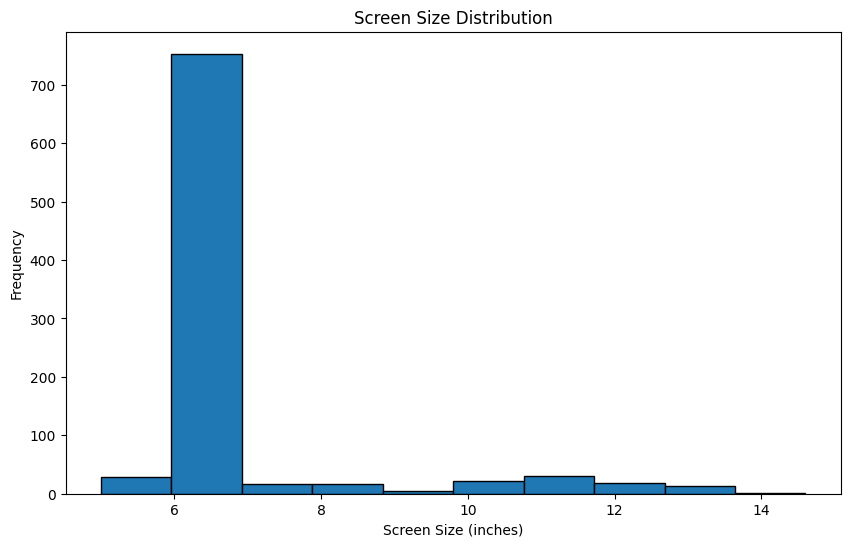

In [19]:
# Visualize screen size distribution using histogram
plt.figure(figsize=(10, 6))
plt.hist(df['Screen Size (inches)'], bins=10, edgecolor='black')
plt.title('Screen Size Distribution')
plt.xlabel('Screen Size (inches)')
plt.ylabel('Frequency')
plt.show()

- What is your insights about above visualization?

The histogram shows that the majority of smartphones have a screen size clustered between 6 and 7 inches. This indicates a standard industry trend towards large displays. There are very few outliers with significantly smaller (< 6 inches) or larger (> 8 inches, likely tablets labeled as phones) screens.

#### 3.4.4. Other Visualization

**Visualization Description:** I created a Boxplot to compare the distribution of Launched Price (USA) for the top 5 most frequent brands in the dataset. This helps us understand the price positioning (budget vs. premium) and the variability of pricing within each brand.

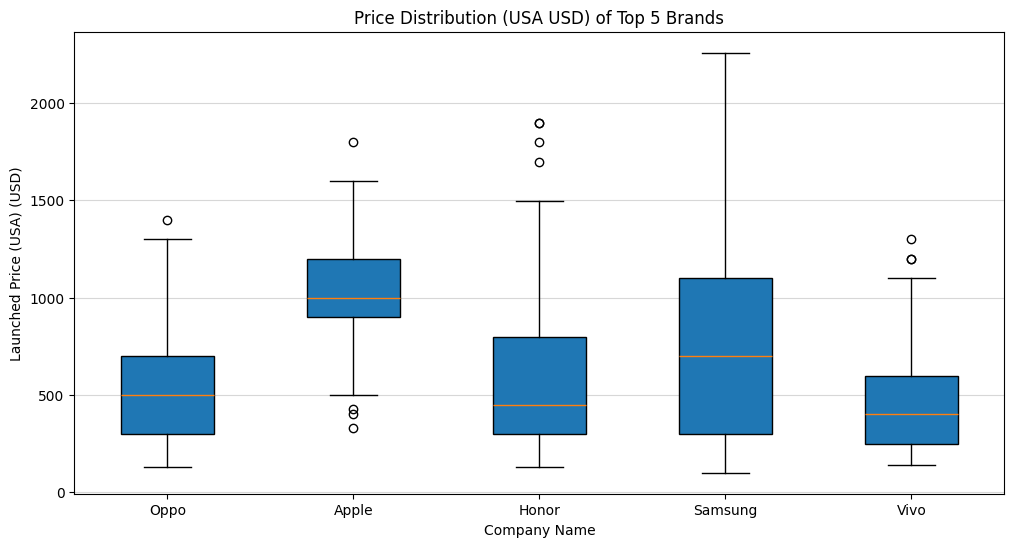

In [20]:
# Visualization: Price Distribution (USA USD) for Top 5 most frequent Brands
top_5_brands = df['Company Name'].value_counts().head(5).index.tolist()
data_to_plot = [df[df['Company Name'] == brand]['Launched Price (USA) (USD)'] for brand in top_5_brands]

plt.figure(figsize=(12, 6))
plt.boxplot(data_to_plot, labels=top_5_brands, patch_artist=True)
plt.title('Price Distribution (USA USD) of Top 5 Brands')
plt.xlabel('Company Name')
plt.ylabel('Launched Price (USA) (USD)')
plt.grid(axis='y', alpha=0.5)
plt.show()

- What is your insights about above visualization?

The boxplot reveals distinct pricing strategies across the leading smartphone brands:

- Apple: Consistently maintains the highest median price (around $1,000) and a high entry point. Its relatively narrow price range (IQR) and lack of low-end models reinforce its status as a strictly premium brand.

- Samsung: Exhibits the widest price range of all brands. While it competes with Apple in the high-end segment, its distribution spans from budget devices to the most expensive ultra-premium models (exceeding $2,250), showing a strategy of total market coverage.

- Oppo and Vivo: Both are primarily positioned in the mid-range segment. Their prices are more concentrated, though Oppo shows a slightly higher median and upper-range ceiling compared to Vivo.

- Honor: Shows a unique "hybrid" strategy. While its median remains low (budget-friendly), the presence of several high-end outliers (up to $1,900) indicates an aggressive push into the luxury flagship market.


## 4. Question proposing & Answering

- In this section, you are going to answer my 2 questions and propose 1 question. Note that these questions can all be answered by analyzing data. Theoretically, the proposed question have to benefit at a certain level. But this is exercise about `Pandas`, my questions can be aimed more at technical side than the meaningful side. But your question has to be meaningful :v

### 4.1. Memory Upgrade

What is the average percentage increase in price when upgrading the memory from 4GB to 8GB?

In [21]:
# What is the average percentage increase in price when upgrading the memory from 4GB to 8GB?
price_4gb = df[df['RAM (GB)'] == 4]['Launched Price (USA) (USD)'].mean()
price_8gb = df[df['RAM (GB)'] == 8]['Launched Price (USA) (USD)'].mean()
percent_increase = ((price_8gb - price_4gb) / price_4gb) * 100
print(f"Average percentage increase: {percent_increase:.2f}%")

Average percentage increase: -12.88%


In [22]:
# TODO (OPTIONAL): Visualize

### 4.2. Relationship Between Device Weight and Battery Capacity

Is there any relationship between device weight and battery capacity?

In [23]:
# Is there any relationship between device weight and battery capacity?
correlation = df['Mobile Weight (g)'].corr(df['Battery Capacity (mAh)'])
print(f"Correlation coefficient: {correlation:.4f}")
# Comment: There is a strong positive correlation, meaning heavier phones tend to have larger batteries.

Correlation coefficient: 0.8480


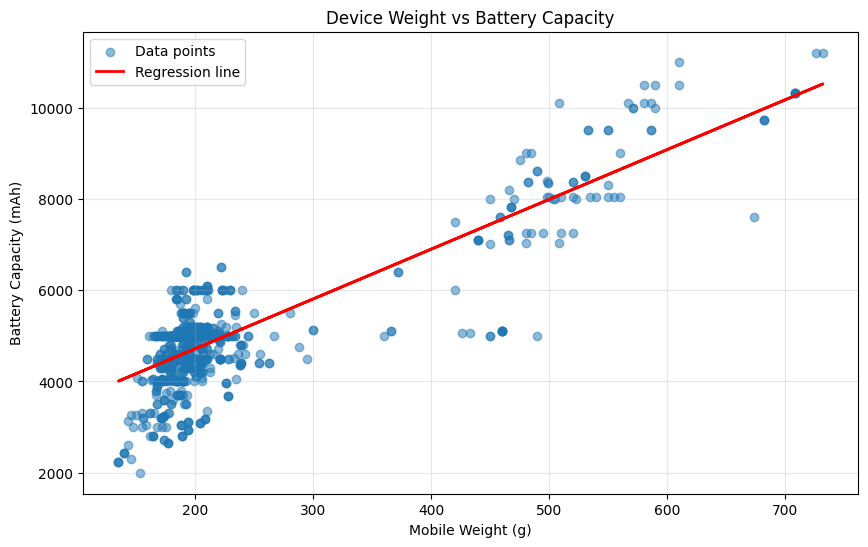

In [24]:
z = np.polyfit(df['Mobile Weight (g)'], df['Battery Capacity (mAh)'], 1)
p = np.poly1d(z)

# Plot
plt.figure(figsize=(10, 6))
plt.scatter(df['Mobile Weight (g)'], df['Battery Capacity (mAh)'], alpha=0.5, label='Data points')
plt.plot(df['Mobile Weight (g)'], p(df['Mobile Weight (g)']), "r", linewidth=2, label='Regression line')
plt.title('Device Weight vs Battery Capacity')
plt.xlabel('Mobile Weight (g)')
plt.ylabel('Battery Capacity (mAh)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### 4.3. Battery Bang for Your Buck
Why Budget Brands Outshine Premium Flagships?

In [25]:
# Top 5 companies offer the best value for money in terms of Battery Capacity per USD
df_valid = df[df['Launched Price (USA) (USD)'] > 0].copy()
df_valid['Battery_per_USD'] = df_valid['Battery Capacity (mAh)'] / df_valid['Launched Price (USA) (USD)']

top_value_companies = df_valid.groupby('Company Name')['Battery_per_USD'].mean().sort_values(ascending=False).head(5)
print("Top 5 Companies by Average Battery Capacity (mAh) per USD:")
print(top_value_companies)

Top 5 Companies by Average Battery Capacity (mAh) per USD:
Company Name
Poco       34.523810
Nokia      27.415435
Infinix    25.336097
Realme     22.972890
Tecno      21.023312
Name: Battery_per_USD, dtype: float64


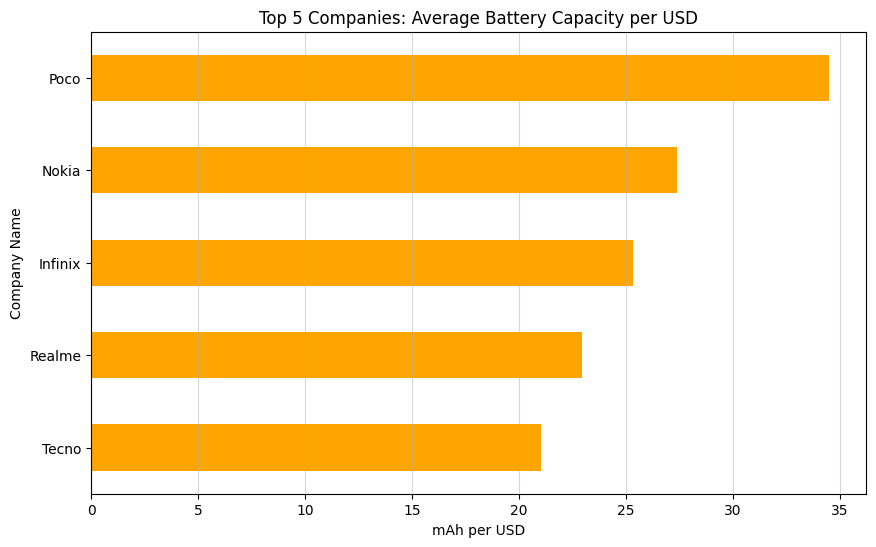

In [26]:
top_value_companies.plot(kind='barh', figsize=(10, 6), color='orange')
plt.title('Top 5 Companies: Average Battery Capacity per USD')
plt.xlabel('mAh per USD')
plt.ylabel('Company Name')
plt.gca().invert_yaxis()
plt.grid(axis='x', alpha=0.5)
plt.show()

Insight for Proposed Question (Battery Capacity per USD):

My proposed question analyzes which companies offer the most 'battery bang for your buck'. The analysis shows that budget-friendly brands like Poco, Nokia, and Infinix offer significantly higher battery capacity per dollar spent compared to premium brands. This suggests that users prioritizing battery life on a budget should look towards these manufacturers, as they provide large batteries at a fraction of the cost of flagship devices.

Well done!